# 02 Manifold - principal-curve trajectory (whole malignant manifold)

Zhang 2019's FL malignant manifold is **non-branching**: the gastrulation (Gast) /
somitogenesis (pSom) / neural-crest (Crest) developmental signatures form one continuous
axis rather than two competing arms. We score the three modules against the union control
pool, graph-smooth for geography, honestly test branching with a PPT tree, then fit a
fold-free principal curve rooted at the developmental origin.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells keep their joint-embedding coordinates - no re-embedding. Modules are scored
with `score_genes` against the union control pool, then graph-smoothed (3x kNN averaging)
for geography reads. Raw per-cell scores are retained for the deliverable UMAPs.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
from numpy.linalg import svd; u,ssv,vt = svd(c, full_matrices=False)
print('UMAP aspect ratio (major/minor std): %.2f' % (ssv[0]/ssv[1]))
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present | mean %+.4f' % (lab, g.size, feat[src].size, adata.obs[lab].mean()))
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 5645 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.57
Gast: 57/81 genes present | mean +0.0117
pSom: 60/98 genes present | mean +0.0062
Crest: 81/104 genes present | mean +0.0092


### Signature geography - non-branching read
Smoothed spatial correlations: Gast and pSom weakly overlap (both at the non-Crest pole)
while **Crest opposes both** - the inverse terminal-gradient signature of a non-branching
manifold, not two competing arms.

In [4]:
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print('  %s vs %s: r = %+.2f' % (a, b, np.corrcoef(adata.obs[a], adata.obs[b])[0,1]))
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = -0.16
  Crest_sm vs Gast_sm: r = -0.54
  Crest_sm vs pSom_sm: r = -0.57


### Honest branching test - PPT tree vs curve
Fit a PPT **tree** and count real branch nodes; check whether any fork separates a
Gast-arm from a pSom-arm. A fork that does not split the modules, and that folds as node
count rises, is not a genuine bifurcation - so we fit a **curve**.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks, B, F
# PPT tree
tr = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(tr, method='ppt', Nodes=30, ppt_lambda=2000, ppt_sigma=.5,
                use_rep='X_umap', seed=SEED, plot=False)
sa,tips,forks,B,F = fold_diag(tr)
tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(tr.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print('PPT tree (Nodes=30): %d tips, %d fork(s), self-approach %.2f' % (tips, forks, sa))
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=4)[0])
    print('  tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' %
          (tp, tr.obs['Gast_sm'][m].mean(), tr.obs['pSom_sm'][m].mean(), tr.obs['Crest_sm'][m].mean()))
print('-> tips are developmentally indistinguishable (no Gast-arm vs pSom-arm); tree folds at higher node counts. Non-branching -> fit a curve.')

PPT tree (Nodes=30): 3 tips, 1 fork(s), self-approach 1.85
  tip 17: Gast=+0.0173 pSom=+0.0043 Crest=+0.0043
  tip 20: Gast=+0.0083 pSom=+0.0040 Crest=+0.0097
  tip 28: Gast=+0.0104 pSom=+0.0114 Crest=+0.0099
-> tips are developmentally indistinguishable (no Gast-arm vs pSom-arm); tree folds at higher node counts. Non-branching -> fit a curve.


In [6]:
# fit the principal curve (fold-free)
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks,Bc,Fc = fold_diag(sub)
print('curve: %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips, forks, sa))
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Derive the root (developmental order)
Root at the curve tip where Gast+pSom is highest and Crest lowest - the developmental
origin (Crest is late). Pseudotime then flows to the neural-crest terminus.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, info[tp][0], info[tp][1], info[tp][2]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print('  %s: rho=%+.3f p=%.1e' % (s, rho, p))

tip 0: Gast=+0.0166 pSom=+0.0040 Crest=+0.0054
tip 2: Gast=+0.0105 pSom=+0.0118 Crest=+0.0096
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.461 p=3.8e-295
  pSom_sm: rho=+0.159 p=3.9e-33
  Crest_sm: rho=+0.334 p=2.3e-147


### Reorient to house style (pseudotime left -> right)
Orient with a discrete axis choice on raw UMAP coordinates (swap/flip, no rotation). This
manifold is near-vertical (pseudotime aligns with the UMAP y-axis), so we swap y->x.

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
rx = np.corrcoef(xy[:,0], t)[0,1]; ry = np.corrcoef(xy[:,1], t)[0,1]
if abs(ry) > abs(rx):
    xyr = np.column_stack([xy[:,1], xy[:,0]]); r = ry; orient = 'swap y->x (near-vertical strip)'
else:
    xyr = np.column_stack([xy[:,0], xy[:,1]]); r = rx; orient = 'identity (already horizontal)'
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
sub.obsm['X_umap_lin'] = xyr
print('orientation:', orient, '| corr(x_lin, pseudotime) = %+.2f' % float(np.corrcoef(xyr[:,0], t)[0,1]))
assert r > 0

orientation: swap y->x (near-vertical strip) | corr(x_lin, pseudotime) = +0.98


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


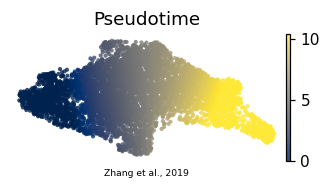

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')